# Linear Regression with Adam Optimizer

This notebook implements the **Adam (Adaptive Moment Estimation)** optimization algorithm from scratch using both **pure Python/NumPy** and **PyTorch** to solve a linear regression problem on synthetic data.

Adam combines the advantages of two other popular extensions of stochastic gradient descent:
- **Adaptive Gradient Algorithm (AdaGrad)** that maintains a per-parameter learning rate that improves performance on problems with sparse gradients.
- **Root Mean Square Propagation (RMSprop)** that also maintains per-parameter learning rates that are adapted based on the average of recent magnitudes of the gradients (first and second raw moments of the gradient).

#### **Import Required Libraries**

- **NumPy** is used for numerical operations and handling arrays.
- **PyTorch** is used for tensor operations and deep learning computations.
- **Matplotlib** is for plotting graphs to visualize results.
- **TQDM** provides a progress bar for loops.
- **Scikit-learn** is used for calculating the R² score, which evaluates our model.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from tqdm import tqdm

pbar_format = "{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}]"

## 1. Helper Function for all GD

### Generate Synthetic Data

We create a function to generate synthetic data that follows a linear relationship.
- **Parameters**:
  - `n`: Number of data points.
  - `bias`: Intercept of the line.
  - `weight`: Slope of the line.
- **Output**: An array containing features and labels.

In [2]:
def synthetic_data(n=100, bias=5, weight=2):
    
    np.random.seed(42)
    torch.manual_seed(42) 
    # Generate synthetic data (linear relationship with some noise)
    bias = 5
    weight = 2
    noise = np.random.randn(n)

    features = np.random.rand(n, 1) * 10
    labels = bias + weight * features.flatten() + noise  # Linear relation with noise

    data = np.hstack((features, labels.reshape(-1, 1)))
    return data

### Visualizing Results

This function will create plots for:
- Loss over epochs
- Values of model parameters (weights)

In [3]:
def plot_results(history, cost_history, lr, fontsize=10, markersize=8):

    history = np.array(history)

    # Create subplots: 3 rows, 1 column
    fig, axs = plt.subplots(history.shape[1] + 1, 1, figsize=(12, 15))  # Adjusted number of rows

    # Plot the loss over epochs
    axs[0].plot(range(len(cost_history)), cost_history, '*-b', markersize=markersize, label='Loss per Epoch')
    axs[0].set_title(f'Loss per Epoch for lr={lr}', fontsize=16, fontweight='bold')
    axs[0].set_xlabel('Iteration', fontsize=fontsize)
    axs[0].set_ylabel('Loss', fontsize=fontsize)
    axs[0].legend()
    axs[0].grid(True)

    # Plot the values of each theta over iterations
    for i in range(history.shape[1]):
        axs[i + 1].plot(history[:, i], '-m.', markersize=markersize, label=f'Theta {i}')
        axs[i + 1].set_title(f'Theta {i} Values over Iterations for lr={lr}', fontsize=fontsize + 4, fontweight='bold')
        axs[i + 1].set_ylabel(f'Theta {i} Value', fontsize=fontsize)
        axs[i + 1].set_xlabel('Iteration', fontsize=fontsize)
        axs[i + 1].grid(True)

    # Adjust layout to prevent overlap
    plt.tight_layout()
    plt.show()

### Evaluate the Model

We define a function to evaluate the model's performance using the R² score:

In [4]:
from sklearn.metrics import r2_score

def evaluate_model(X, y, theta):
    predictions = X @ theta
    return r2_score(y, predictions)

### (optional) Use Decorators to Display Pretty Report after Training

In [5]:
def report_decorator(func):
    def wrapper(*args, **kwargs):

        result = func(*args, **kwargs) 
        epoch, weights_history, cost_history, r2 = result
        
        print("="*60)
        print(" "*20, "Final Training Report")
        print("="*60)
        print(f"🟢 Total Epochs Run : {epoch+1}")
        print(f"🟢 Final MSE        : {cost_history[-1]:.3f}")
        print(f"🟢 Final R-square   : {r2:.3f}")
        print(f"🟢 Final Weights    : [{' '.join(f'{float(w):.4f}' for w in weights_history[-1].flatten())}]")
        print("="*60)
        
        return result
    
    return wrapper

### (optional) Use Decorators to Calculate Time Duration of the Training

In [6]:
import time

def time_decorator(func):
    def training(*args, **kwargs):
        start_time = time.time()        # Start time
        result = func(*args, **kwargs)  # Call the function
        end_time = time.time()          # End time
        print(f"Time taken for {func.__name__}: {end_time - start_time:.4f} seconds")
        return result
    return training

## 2. Adam Optimizer Using Python

The `Adam_python` function implements the **Adam (Adaptive Moment Estimation)** algorithm using **Python** to optimize the parameters (weights) of a linear regression model.

### Key Features of Adam Optimizer
- **First Moment Estimation ($m_t$)**: Keeps an exponentially decaying average of past gradients (like Momentum):
  $$m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t$$
- **Second Moment Estimation ($v_t$)**: Keeps an exponentially decaying average of past squared gradients (like RMSprop):
  $$v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2$$
- **Bias Correction**: Corrects the initialization bias of moments toward zero during initial time steps:
  $$\hat{m}_t = \frac{m_t}{1 - \beta_1^t}, \quad \hat{v}_t = \frac{v_t}{1 - \beta_2^t}$$
- **Parameter Update**: Updates the parameters adaptively per feature:
  $$\theta_{t+1} = \theta_t - \frac{\alpha}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$$

### Key Steps
1. **Initialization**: Initialize weights $\theta$, 1st moment vector $m$, and 2nd moment vector $v$ with zeros.
2. **Prediction**: Compute predictions using current weights: $h_\theta(X) = X \theta$.
3. **Loss & Gradient**: Calculate the MSE loss and gradient of loss with respect to parameters.
4. **Moment Updates & Bias Correction**: Update biased 1st and 2nd moments, then apply bias corrections.
5. **Parameter Update**: Adjust weights using adaptive learning rates, followed by checking convergence.

### Hyperparameters
- `learning_rate` ($\alpha$): Step size taken towards the minimum (e.g., `0.01` or `0.001`).
- `beta1` ($\beta_1$): Exponential decay rate for first moment estimates (default: `0.9`).
- `beta2` ($\beta_2$): Exponential decay rate for second-moment estimates (default: `0.999`).
- `epsilon` ($\epsilon$): Very small number to prevent division by zero (default: `1e-8`).
- `epochs`: Maximum number of iterations through the dataset.
- `tolerance`: Threshold for early stopping when loss improvement is negligible.

### Implementing Adam Optimizer Using Python

In [7]:
@time_decorator
@report_decorator
def Adam_python(X, y, **hyperparams):
    
    np.random.seed(42)
    
    # Extract hyperparameters or set default values
    learning_rate = hyperparams.get('learning_rate', 0.01)
    epochs = hyperparams.get('epochs', 10_000)
    tolerance = hyperparams.get('tolerance', 0.001)
    beta1 = hyperparams.get('beta1', 0.9)
    beta2 = hyperparams.get('beta2', 0.999)
    epsilon = hyperparams.get('epsilon', 1e-8)
    
    X = np.insert(X, 0, 1, axis=1)      # Add bias term
    y = y.reshape(-1, 1)                # Reshape y to a column vector
    m, n = X.shape                      # Number of training examples and features

    cost_history = []                   # Store all losses per iteration
    weights_history = []                # Store all weights per iteration
    theta = np.zeros((n, 1))            # Initialize theta with zeros
    m_t = np.zeros((n, 1))              # Initialize 1st moment vector with zeros
    v_t = np.zeros((n, 1))              # Initialize 2nd moment vector with zeros
    weights_history.append(theta.copy())

    # Progress bar for visual feedback
    pbar = tqdm(total=epochs, colour='green', ncols=150)
    
    for epoch in range(epochs):
        t = epoch + 1                   # Timestep for bias correction

        # 1. Predict output using current theta (weights)
        h_x = X @ theta

        # 2. Calculate Error for all instances
        e = (h_x - y)
        loss = np.sum(e ** 2) / (2 * m)  # Mean Squared Error (MSE) as loss
        cost_history.append(loss)

        # 3. Calculate gradient
        gradient = (X.T @ e) / m

        # 4. Update biased 1st and 2nd moment estimate
        m_t = beta1 * m_t + (1 - beta1) * gradient
        v_t = beta2 * v_t + (1 - beta2) * (gradient ** 2)

        # 5. Compute bias-corrected 1st and 2nd moment estimate
        m_hat = m_t / (1 - beta1 ** t)
        v_hat = v_t / (1 - beta2 ** t)

        # 6. Update weights
        theta = theta - (learning_rate / (np.sqrt(v_hat) + epsilon)) * m_hat

        # Store weights history
        weights_history.append(theta.copy())

        # Optional: Early stopping and convergence check
        if epoch > 0:
            if abs(cost_history[-1] - cost_history[-2]) < tolerance:
                print(f"Convergence reached at epoch {epoch + 1}.")
                break

        # optional Calculate r2 Score
        r2 = evaluate_model(X, y, theta) 
        # Print progress
        pbar.set_description(f"Epoch [{epoch+1}/{epochs}] - Loss: {loss:.6f} - r2: {r2:.3f} - Weights: {theta.flatten()}")
        pbar.update(1)

    pbar.close()

    return epoch, weights_history, cost_history, r2

### Run the Model

It's essential to understand how different parameters affect the performance of the model. I encourage you to:

1. **Change the Number of Data Points**:
   - Modify the `n` parameter in the `synthetic_data` function and Observe how the amount of training data influences the model's performance and convergence speed.
   - **Example:** Try using `10, 50, 200, or 500` data points.
   - **Note:** This will help you understand how the model's performance scales with the amount of training data.

2. **Adjust the Learning Rate**:
   - Experiment with different **learning rates** in the `Adam_python` function and Observe how the **learning rate** affects convergence.
   - **Example:** Common values to try include `0.1, 0.01, and 0.001`.
   - **Note:** A learning rate that is too high can cause the model to oscillate before convergence, while a learning rate that is too low can slow down convergence.

3. **Adjust the Momentum & Decay Coefficients (Beta1 and Beta2)**:
   - Experiment with different decay values for $\beta_1$ (e.g., `0.8, 0.9, 0.95`) and $\beta_2$ (e.g., `0.99, 0.999`).
   - **Note:** Higher $\beta_1$ places more emphasis on earlier gradients, while $\beta_2$ controls how quickly the second moment adapts to scale.

4. **Adjust the Epochs Numbers**:
   - Experiment with different numbers of **epochs** in the `Adam_python` function. Observe how the number of **epochs** affects the model's performance and convergence.
   - **Example:** try `100, 500, or 1000` epochs.
   - **Note:** A larger number of epochs may lead to better convergence but may also increase training time.

### Use Small Learning Rate

In [8]:
# Generate 50 synthetic data points
data = synthetic_data(n=50, bias=5, weight=2)
X, y = data[:, :-1], data[:, -1]
print(f"X: {X}\n \n y: {y}")

X: [[1.40924225]
 [8.02196981]
 [0.74550644]
 [9.86886937]
 [7.72244769]
 [1.98715682]
 [0.05522117]
 [8.15461428]
 [7.06857344]
 [7.29007168]
 [7.71270347]
 [0.74044652]
 [3.58465729]
 [1.1586906 ]
 [8.63103426]
 [6.23298127]
 [3.30898025]
 [0.6355835 ]
 [3.10982322]
 [3.25183322]
 [7.29606178]
 [6.37557471]
 [8.87212743]
 [4.72214925]
 [1.19594246]
 [7.13244787]
 [7.60785049]
 [5.61277198]
 [7.7096718 ]
 [4.93795596]
 [5.22732829]
 [4.27541018]
 [0.25419127]
 [1.07891427]
 [0.31429186]
 [6.36410411]
 [3.14355981]
 [5.08570691]
 [9.07566474]
 [2.49292229]
 [4.10382923]
 [7.55551139]
 [2.28798165]
 [0.7697991 ]
 [2.89751453]
 [1.61221287]
 [9.29697652]
 [8.0812038 ]
 [6.33403757]
 [8.7146059 ]]
 
 y: [ 8.31519865 20.90567531  7.13870141 26.26076859 20.21074201  8.74017667
  6.68965516 22.0766633  18.66767249 20.1227034  19.96198924  6.01516328
 12.41127684  5.40410095 20.53715068 16.90367501 10.60512938  6.58541434
 10.31162236 10.09136274 21.05777234 17.52537313 22.81178306 13.0195503

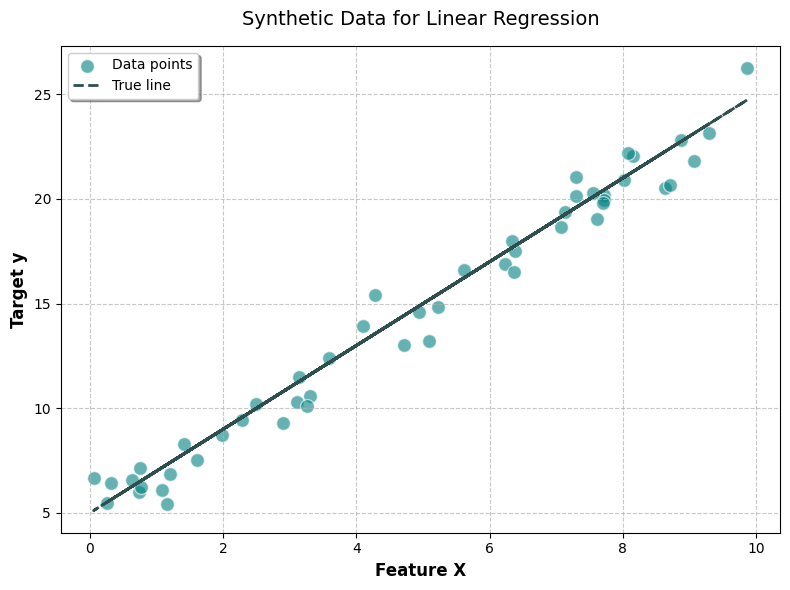

In [9]:
# Plot synthetic data points
plt.figure(figsize=(8, 6))
plt.scatter(X, y, color='teal', alpha=0.6, s=100, edgecolor='white', label='Data points')
plt.plot(X, 5 + 2 * X, color='darkslategray', linewidth=2, linestyle='--', label='True line')
plt.xlabel('Feature X', fontsize=12, fontweight='bold')
plt.ylabel('Target y', fontsize=12, fontweight='bold')
plt.title('Synthetic Data for Linear Regression', fontsize=14, pad=15)
plt.legend(frameon=True, fancybox=True, shadow=True, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Epoch [544/10000] - Loss: 1.120458 - r2: 0.938 - Weights: [2.59526668 2.30768426]:   5%|█▎                       | 544/10000 [00:01<00:20, 462.65it/s]


Convergence reached at epoch 545.
                     Final Training Report
🟢 Total Epochs Run : 545
🟢 Final MSE        : 1.119
🟢 Final R-square   : 0.938
🟢 Final Weights    : [2.5965 2.3079]
Time taken for wrapper: 1.1811 seconds


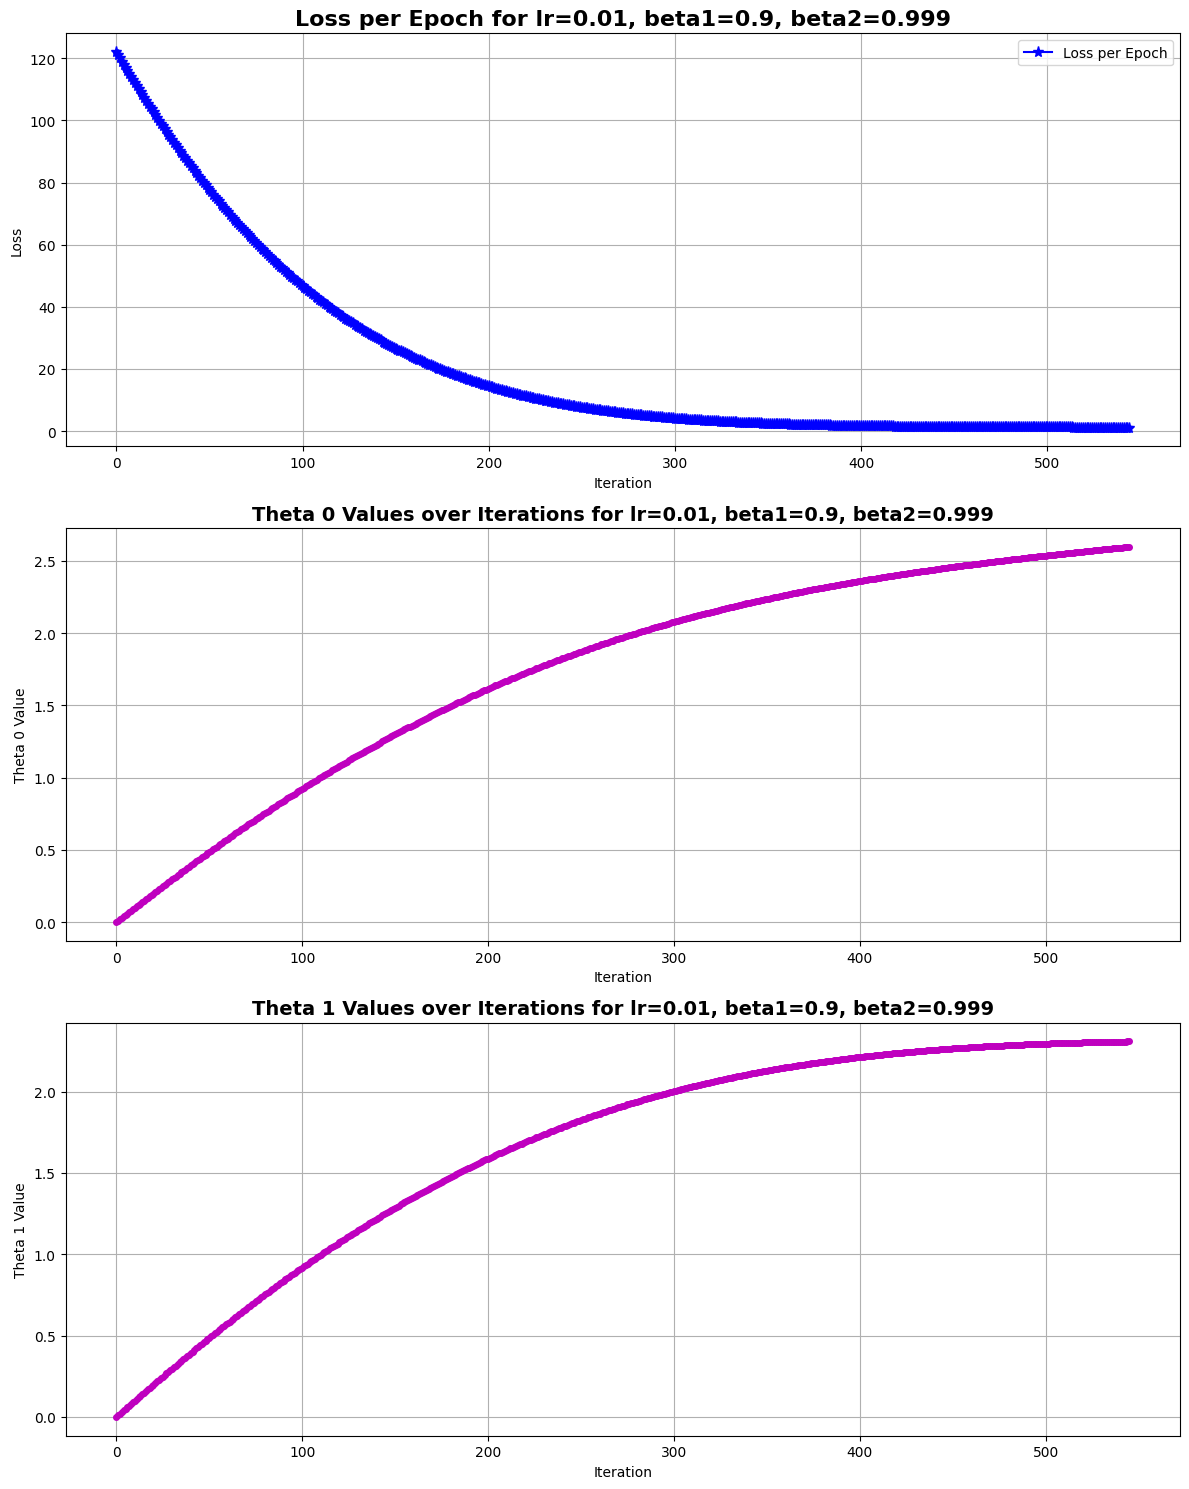

In [10]:
# Initialize hyperparameters
lr = 0.01
b1 = 0.9
b2 = 0.999

# Run Adam Optimizer
_, weights_history, cost_history, r2 = Adam_python(X, y, learning_rate=lr, beta1=b1, beta2=b2)

# Plot results
plot_results(weights_history, cost_history, lr=f"{lr}, beta1={b1}, beta2={b2}")

### Use Large Learning Rate

Epoch [68/10000] - Loss: 1.032234 - r2: 0.943 - Weights: [2.74003497 2.28809198]:   1%|▏                          | 68/10000 [00:00<00:22, 445.30it/s]


Convergence reached at epoch 69.
                     Final Training Report
🟢 Total Epochs Run : 69
🟢 Final MSE        : 1.032
🟢 Final R-square   : 0.943
🟢 Final Weights    : [2.7454 2.2815]
Time taken for wrapper: 0.1580 seconds


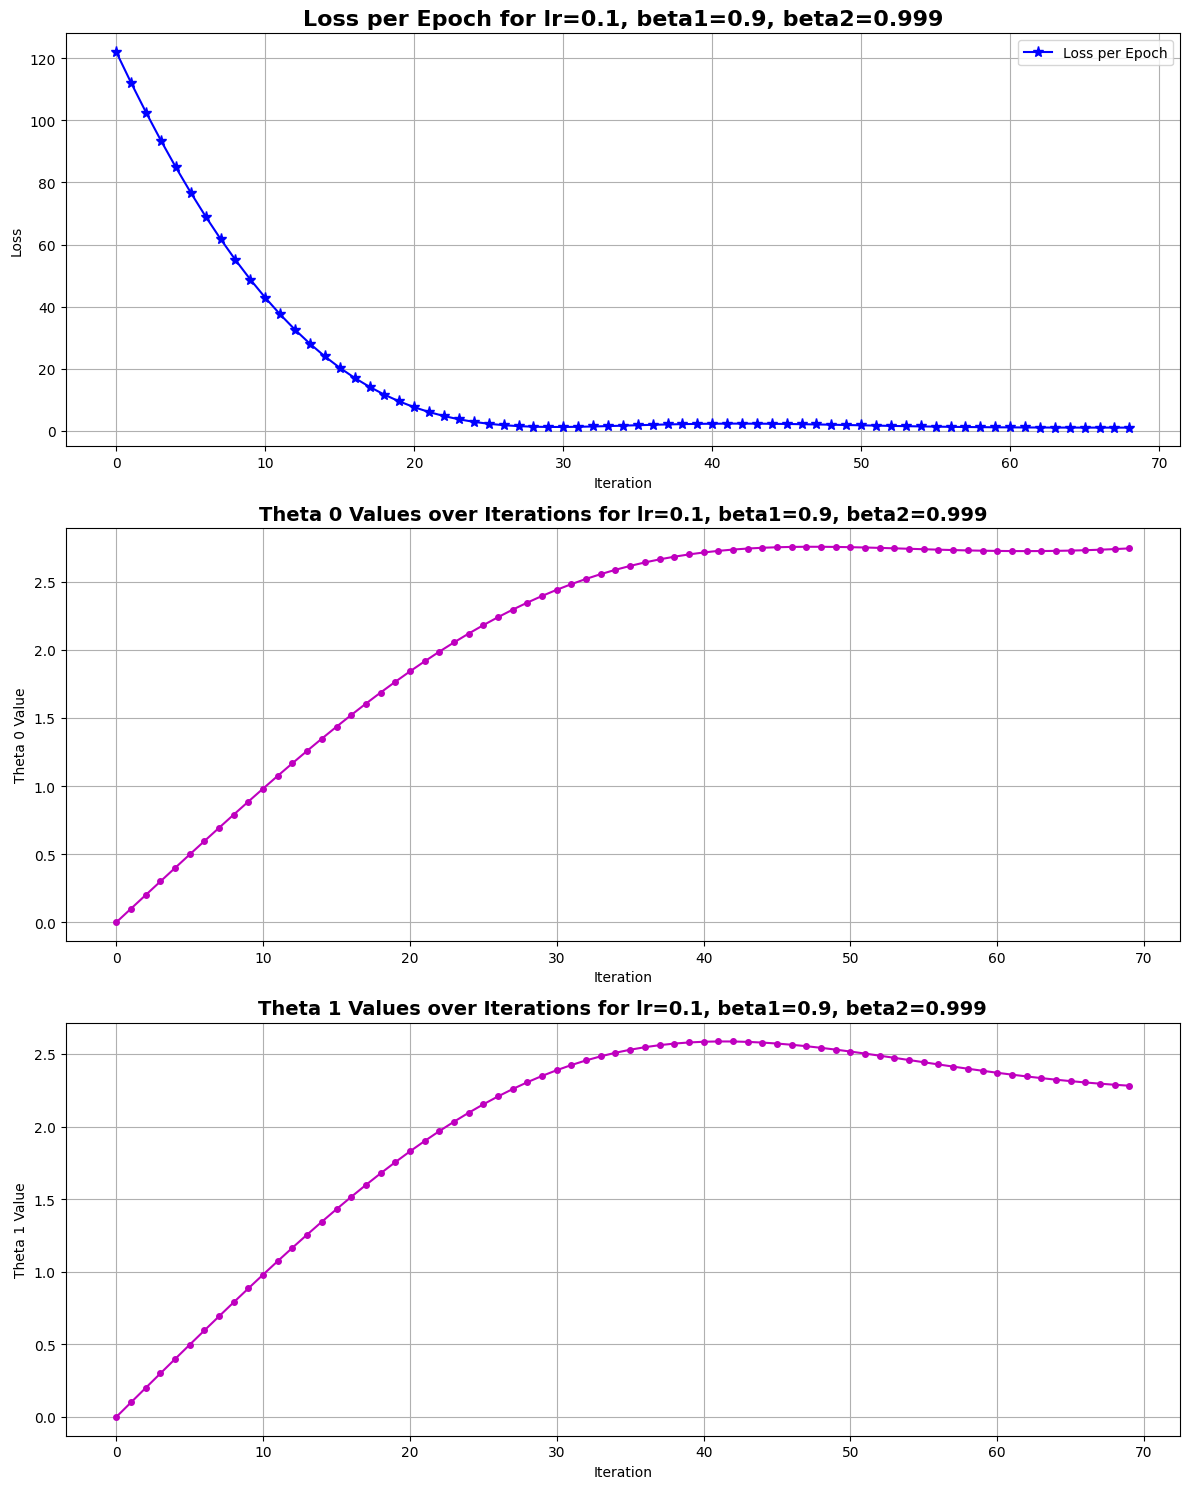

In [11]:
# Initialize hyperparameters
lr = 0.1
b1 = 0.9
b2 = 0.999

# Run Adam Optimizer
_, weights_history, cost_history, r2 = Adam_python(X, y, learning_rate=lr, beta1=b1, beta2=b2)

# Plot results
plot_results(weights_history, cost_history, lr=f"{lr}, beta1={b1}, beta2={b2}")

> **Adam (Adaptive Moment Estimation)** combines the advantages of **Momentum** (storing an exponentially decaying average of past gradients $m_t$) and **RMSprop** (storing an exponentially decaying average of past squared gradients $v_t$), with **bias correction** terms to counteract the zero-initialization bias during initial steps. This adaptive scaling makes Adam robust across diverse gradient scales and highly efficient at finding optimal parameters.

## 3. Adam Optimizer Using PyTorch

The `Adam_torch` function implements the **Adam** optimization algorithm using **PyTorch** to optimize the parameters (weights) of a linear regression model.

**Key Changes from the Python Code:**
1. **Data Conversion**: The input data `X` and `y` are converted to PyTorch tensors with `dtype=torch.float32`.
2. **Bias Term**: The bias term is added to `X` before converting to tensors.
3. **Gradient Calculation**: The gradient is calculated using tensor matrix multiplication (`X_tensor.T @ e`).
4. **Moment & Weight Tensors**: The moments ($m_t, v_t$) and weights ($\theta$) are updated using element-wise tensor arithmetic (`torch.sqrt`).
5. **Loss Tracking**: Losses are appended as Python numbers using `.item()`.

### Implementing Adam Optimizer Using PyTorch

In [12]:
@time_decorator
@report_decorator
def Adam_torch(X, y, **hyperparams):
    
    np.random.seed(42)
    torch.manual_seed(42)
    
    # Extract hyperparameters or set default values
    learning_rate = hyperparams.get('learning_rate', 0.01)
    epochs = hyperparams.get('epochs', 10_000)
    tolerance = hyperparams.get('tolerance', 0.001)
    beta1 = hyperparams.get('beta1', 0.9)
    beta2 = hyperparams.get('beta2', 0.999)
    epsilon = hyperparams.get('epsilon', 1e-8)
    
    X = np.insert(X, 0, 1, axis=1)      # Add bias term
    y = y.reshape(-1, 1)
    m, n = X.shape                      # Number of training examples and features

    # Convert to PyTorch tensors
    X_tensor = torch.tensor(X, dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.float32)

    cost_history = []                                    # Store all losses per iteration
    weights_history = []                                 # Store all weights per iteration
    theta = torch.zeros((n, 1), dtype=torch.float32)     # Initialize theta with zeros
    m_t = torch.zeros((n, 1), dtype=torch.float32)       # Initialize 1st moment with zeros
    v_t = torch.zeros((n, 1), dtype=torch.float32)       # Initialize 2nd moment with zeros
    weights_history.append(theta.clone().numpy())

    # Progress bar for visual feedback
    pbar = tqdm(total=epochs, colour='green', ncols=150)
    
    for epoch in range(epochs):
        t = epoch + 1

        # 1. Predict output using current theta (weights)
        h_x = X_tensor @ theta

        # 2. Calculate Error for all instances
        e = (h_x - y_tensor)
        loss = torch.sum(e ** 2) / (2 * m)  # Mean Squared Error (MSE) as loss
        cost_history.append(loss.item())

        # 3. Calculate gradient
        gradient = (X_tensor.T @ e) / m

        # 4. Update biased 1st and 2nd moment estimate
        m_t = beta1 * m_t + (1 - beta1) * gradient
        v_t = beta2 * v_t + (1 - beta2) * (gradient ** 2)

        # 5. Compute bias-corrected 1st and 2nd moment estimate
        m_hat = m_t / (1 - beta1 ** t)
        v_hat = v_t / (1 - beta2 ** t)

        # 6. Update weights
        theta = theta - (learning_rate / (torch.sqrt(v_hat) + epsilon)) * m_hat

        # Store weights history
        weights_history.append(theta.clone().detach().numpy())

        # Optional: Early stopping and convergence check
        if epoch > 0:
            if abs(cost_history[-1] - cost_history[-2]) < tolerance:
                print(f"Convergence reached at epoch {epoch + 1}.")
                break

        # optional Calculate r2 Score
        r2 = evaluate_model(X, y, theta.detach().numpy())
        # Print progress
        pbar.set_description(f"Epoch [{epoch+1}/{epochs}] - Loss: {loss.item():.6f} - r2: {r2:.3f} - Weights: {theta.flatten().detach().numpy()}")
        pbar.update(1)

    pbar.close()

    return epoch, weights_history, cost_history, r2

### Run the Model

Just like the Python implementation, test the model with different hyperparameters using PyTorch.

### Use Small Learning Rate

Epoch [544/10000] - Loss: 1.120460 - r2: 0.938 - Weights: [2.5952642 2.307684 ]:   5%|█▍                         | 544/10000 [00:01<00:28, 335.90it/s]


Convergence reached at epoch 545.
                     Final Training Report
🟢 Total Epochs Run : 545
🟢 Final MSE        : 1.119
🟢 Final R-square   : 0.938
🟢 Final Weights    : [2.5965 2.3079]
Time taken for wrapper: 1.6934 seconds


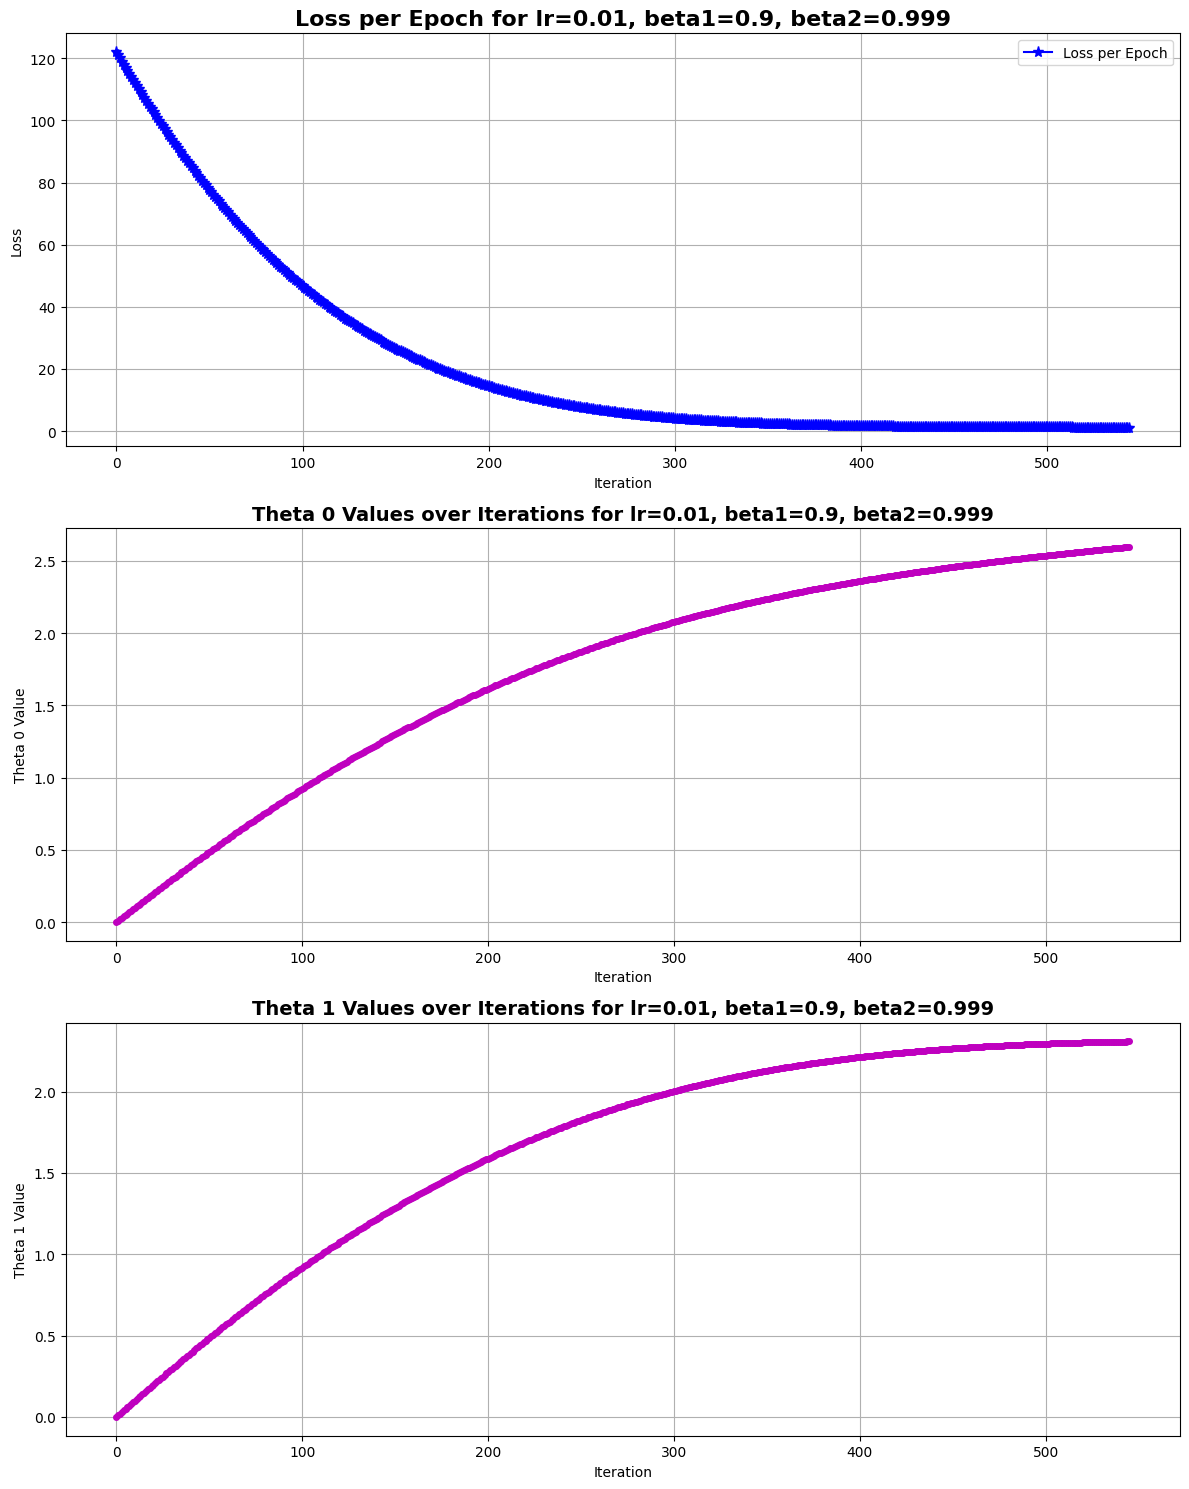

In [13]:
# Initialize hyperparameters
lr = 0.01
b1 = 0.9
b2 = 0.999

# Run Adam Optimizer with PyTorch
_, weights_history, cost_history, r2 = Adam_torch(X, y, learning_rate=lr, beta1=b1, beta2=b2)

# Plot results
plot_results(weights_history, cost_history, lr=f"{lr}, beta1={b1}, beta2={b2}")

### Use Large Learning Rate

Epoch [68/10000] - Loss: 1.032233 - r2: 0.943 - Weights: [2.7400353 2.288092 ]:   1%|▏                            | 68/10000 [00:00<00:29, 339.37it/s]


Convergence reached at epoch 69.
                     Final Training Report
🟢 Total Epochs Run : 69
🟢 Final MSE        : 1.032
🟢 Final R-square   : 0.943
🟢 Final Weights    : [2.7454 2.2815]
Time taken for wrapper: 0.2099 seconds


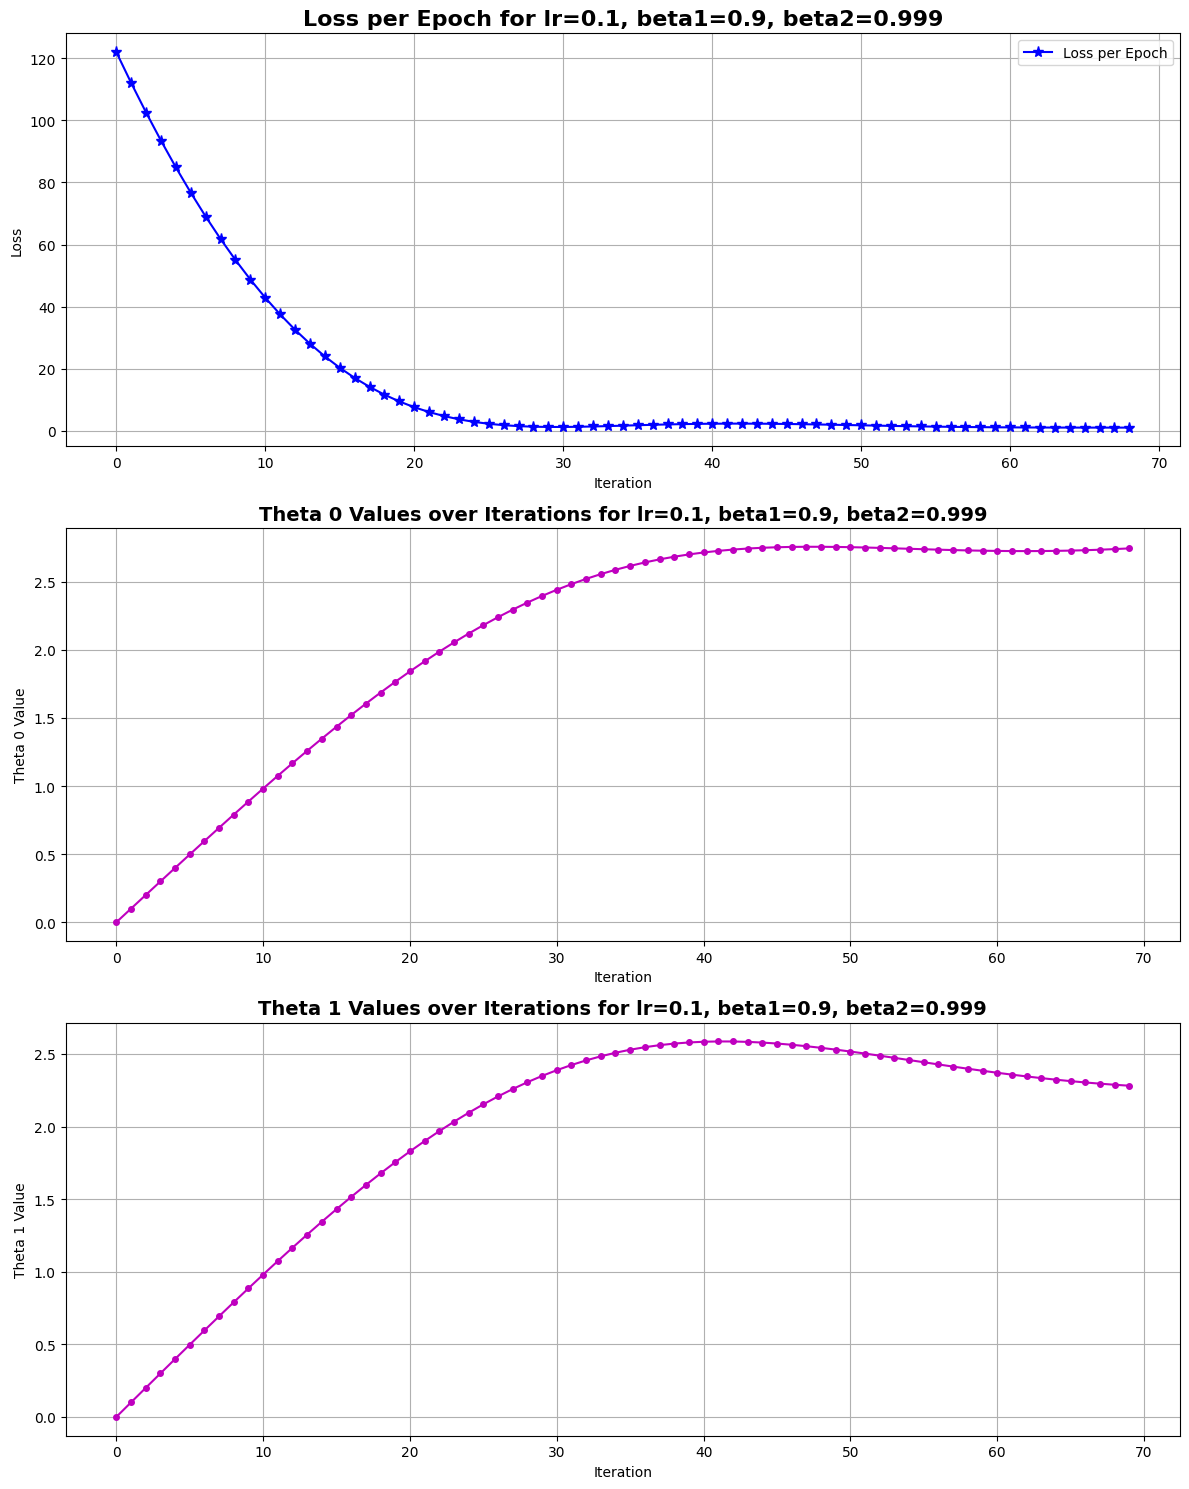

In [14]:
# Initialize hyperparameters
lr = 0.1
b1 = 0.9
b2 = 0.999

# Run Adam Optimizer with PyTorch
_, weights_history, cost_history, r2 = Adam_torch(X, y, learning_rate=lr, beta1=b1, beta2=b2)

# Plot results
plot_results(weights_history, cost_history, lr=f"{lr}, beta1={b1}, beta2={b2}")